# 32 · Field and budget

**Question.** How accurate is the field decoded from the prepared state, and where does its error come from?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p5_stateprep",)
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p5_stateprep: 338 records, 338 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import primary_preparations

forms = {
    form: [
        r
        for r in primary_preparations(results.rows("p5_stateprep", regime=form))
        if r["field_err_linf"] != ""
    ]
    for form in ("standard", "descriptor")
}


def verdict(form, rows):
    """Return one line: the records within the field bound, and the discretisation's share."""
    judged = [r for r in rows if isinstance(r["field_within_bound"], bool)]
    misses = [r for r in judged if not r["field_within_bound"]]
    named = ", ".join(
        f"{r['problem']} at n = {r['n']}" + ("" if r["trusted"] else " (untrusted)") for r in misses
    )
    terms = ("field_filter", "field_truncation", "field_phases")
    budgeted = [r for r in judged if all(isinstance(r[k], float) for k in terms)]
    first = sum(r["eps_disc"] >= sum(r[k] for k in terms) for r in budgeted)
    return (
        f"- The {form} form: {len(judged) - len(misses)} of the {len(judged)} records where the "
        f"bound holds are within it{'; outside it: ' + named if misses else ''}. The "
        f"discretisation error exceeds the state's terms together in {first} of the "
        f"{len(budgeted)} whose every term the budget bounds."
    )


display(Markdown("\n".join(verdict(form, rows) for form, rows in forms.items())))

- The standard form: 39 of the 39 records where the bound holds are within it. The discretisation error exceeds the state's terms together in 25 of the 39 whose every term the budget bounds.
- The descriptor form: 88 of the 88 records where the bound holds are within it. The discretisation error exceeds the state's terms together in 28 of the 88 whose every term the budget bounds.

Left, the decoded field's error against the bound the state's distance sets, which holds wherever
that distance is small enough to decode. Right, the same error against the discretisation's own, the
reference field's error: on the diagonal, the state adds nothing.

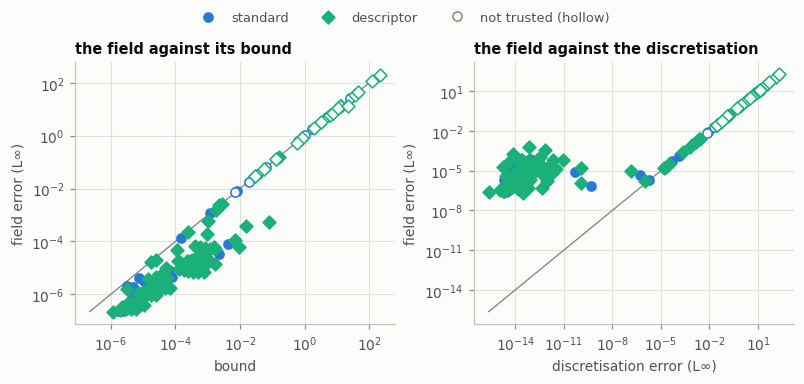

In [3]:
plotting.checks(
    [
        plotting.Check(
            forms,
            "field_bound",
            "field_err_linf",
            "bound",
            "field error (L∞)",
            "the field against its bound",
        ),
        plotting.Check(
            forms,
            "eps_disc",
            "field_err_linf",
            "discretisation error (L∞)",
            "field error (L∞)",
            "the field against the discretisation",
        ),
    ]
);

**What this does not show.** The field is read out classically from the prepared state; the paper's
interferometric readout (`pihm.qsp.readout`) is not run here. The budget's encoding and sampling terms are
zero here: every encoding prepared is exact, and nothing is sampled.